In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

/kaggle/input/playground-series-s5e12/sample_submission.csv
/kaggle/input/playground-series-s5e12/train.csv
/kaggle/input/playground-series-s5e12/test.csv


#  Diabetes Prediction Challenge - CatBoost | LightGBM

## Introduction
In this notebook, we aim to predict the diagnosis of diabetes using a dataset containing various health indicators. We will perform Exploratory Data Analysis (EDA) to understand the data distribution and relationships, followed by training a Gradient Boosting model using **CatBoost** and **LightGBM**.



## Importing Libraries
First, we import the necessary libraries for data manipulation, visualization, and numerical operations.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

## Loading the Dataset
We load the training and testing datasets. We also separate the `id` column from the test set as it will be required for the final submission file.

In [3]:
train_df = pd.read_csv('/kaggle/input/playground-series-s5e12/train.csv')
test_df = pd.read_csv('/kaggle/input/playground-series-s5e12/test.csv')

# Save test IDs for submission
test_ids = test_df['id']

## Data Overview & Quality Check
Let's inspect the structure of the data, data types, and check for any missing values. It is crucial to ensure that the dataset is clean before proceeding to analysis.

In [4]:
print("--- Train Set Info ---")
train_df.info()

print("\n--- Test Set Info ---")
test_df.info()

print("\n--- Missing Values in Train Set ---")
print(train_df.isnull().sum())

print("\n--- Missing Values in Test Set ---")
print(test_df.isnull().sum())

--- Train Set Info ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 700000 entries, 0 to 699999
Data columns (total 26 columns):
 #   Column                              Non-Null Count   Dtype  
---  ------                              --------------   -----  
 0   id                                  700000 non-null  int64  
 1   age                                 700000 non-null  int64  
 2   alcohol_consumption_per_week        700000 non-null  int64  
 3   physical_activity_minutes_per_week  700000 non-null  int64  
 4   diet_score                          700000 non-null  float64
 5   sleep_hours_per_day                 700000 non-null  float64
 6   screen_time_hours_per_day           700000 non-null  float64
 7   bmi                                 700000 non-null  float64
 8   waist_to_hip_ratio                  700000 non-null  float64
 9   systolic_bp                         700000 non-null  int64  
 10  diastolic_bp                        700000 non-null  int64  
 11  hea

### Previewing the Data
Displaying the first few rows to understand the feature values and scales.

In [5]:
train_df.head()

,id,age,alcohol_consumption_per_week,physical_activity_minutes_per_week,diet_score,sleep_hours_per_day,screen_time_hours_per_day,bmi,waist_to_hip_ratio,systolic_bp,...,gender,ethnicity,education_level,income_level,smoking_status,employment_status,family_history_diabetes,hypertension_history,cardiovascular_history,diagnosed_diabetes
0,0,31,1,45,7.7,6.8,6.1,33.4,0.93,112,...,Female,Hispanic,Highschool,Lower-Middle,Current,Employed,0,0,0,1.0
1,1,50,2,73,5.7,6.5,5.8,23.8,0.83,120,...,Female,White,Highschool,Upper-Middle,Never,Employed,0,0,0,1.0
2,2,32,3,158,8.5,7.4,9.1,24.1,0.83,95,...,Male,Hispanic,Highschool,Lower-Middle,Never,Retired,0,0,0,0.0
3,3,54,3,77,4.6,7.0,9.2,26.6,0.83,121,...,Female,White,Highschool,Lower-Middle,Current,Employed,0,1,0,1.0
4,4,54,1,55,5.7,6.2,5.1,28.8,0.90,108,...,Male,White,Highschool,Upper-Middle,Never,Retired,0,1,0,1.0


## Consistency Check: Train vs. Test Categories
In machine learning, it's vital to ensure that the categorical features in the test set match those in the training set. If the test set contains unseen categories, the model might fail or produce incorrect predictions. The following loop checks for any discrepancies.

In [6]:
categorical_cols = train_df.select_dtypes(include=['object']).columns

print("--- Categorical Variable Comparison ---\n")

for col in categorical_cols:
    print(f"Column: {col}")

    train_vals = set(train_df[col].unique())
    test_vals = set(test_df[col].unique())

    only_in_train = train_vals - test_vals
    only_in_test = test_vals - train_vals

    print(f"Train value count: {len(train_vals)}")
    print(f"Test value count : {len(test_vals)}")

    if only_in_train:
        print(f"-> Present in Train but NOT in Test: {only_in_train}")

    if only_in_test:
        print(f"-> WARNING: Present in Test but NOT in Train: {only_in_test}")
        print("   (This might cause errors in the model!)")
    else:
        print("-> OK: All values in Test are known in Train.")

    print("-" * 50 + "\n")

--- Categorical Variable Comparison ---

Column: gender
Train value count: 3
Test value count : 3
-> OK: All values in Test are known in Train.
--------------------------------------------------

Column: ethnicity
Train value count: 5
Test value count : 5
-> OK: All values in Test are known in Train.
--------------------------------------------------

Column: education_level
Train value count: 4
Test value count : 4
-> OK: All values in Test are known in Train.
--------------------------------------------------

Column: income_level
Train value count: 5
Test value count : 5
-> OK: All values in Test are known in Train.
--------------------------------------------------

Column: smoking_status
Train value count: 3
Test value count : 3
-> OK: All values in Test are known in Train.
--------------------------------------------------

Column: employment_status
Train value count: 4
Test value count : 4
-> OK: All values in Test are known in Train.
--------------------------------------------

## Exploratory Data Analysis (EDA)
We visualize the relationship between the target variable `diagnosed_diabetes` and key features such as **Smoking Status** and **Income Level**. This helps us identify potential risk factors.

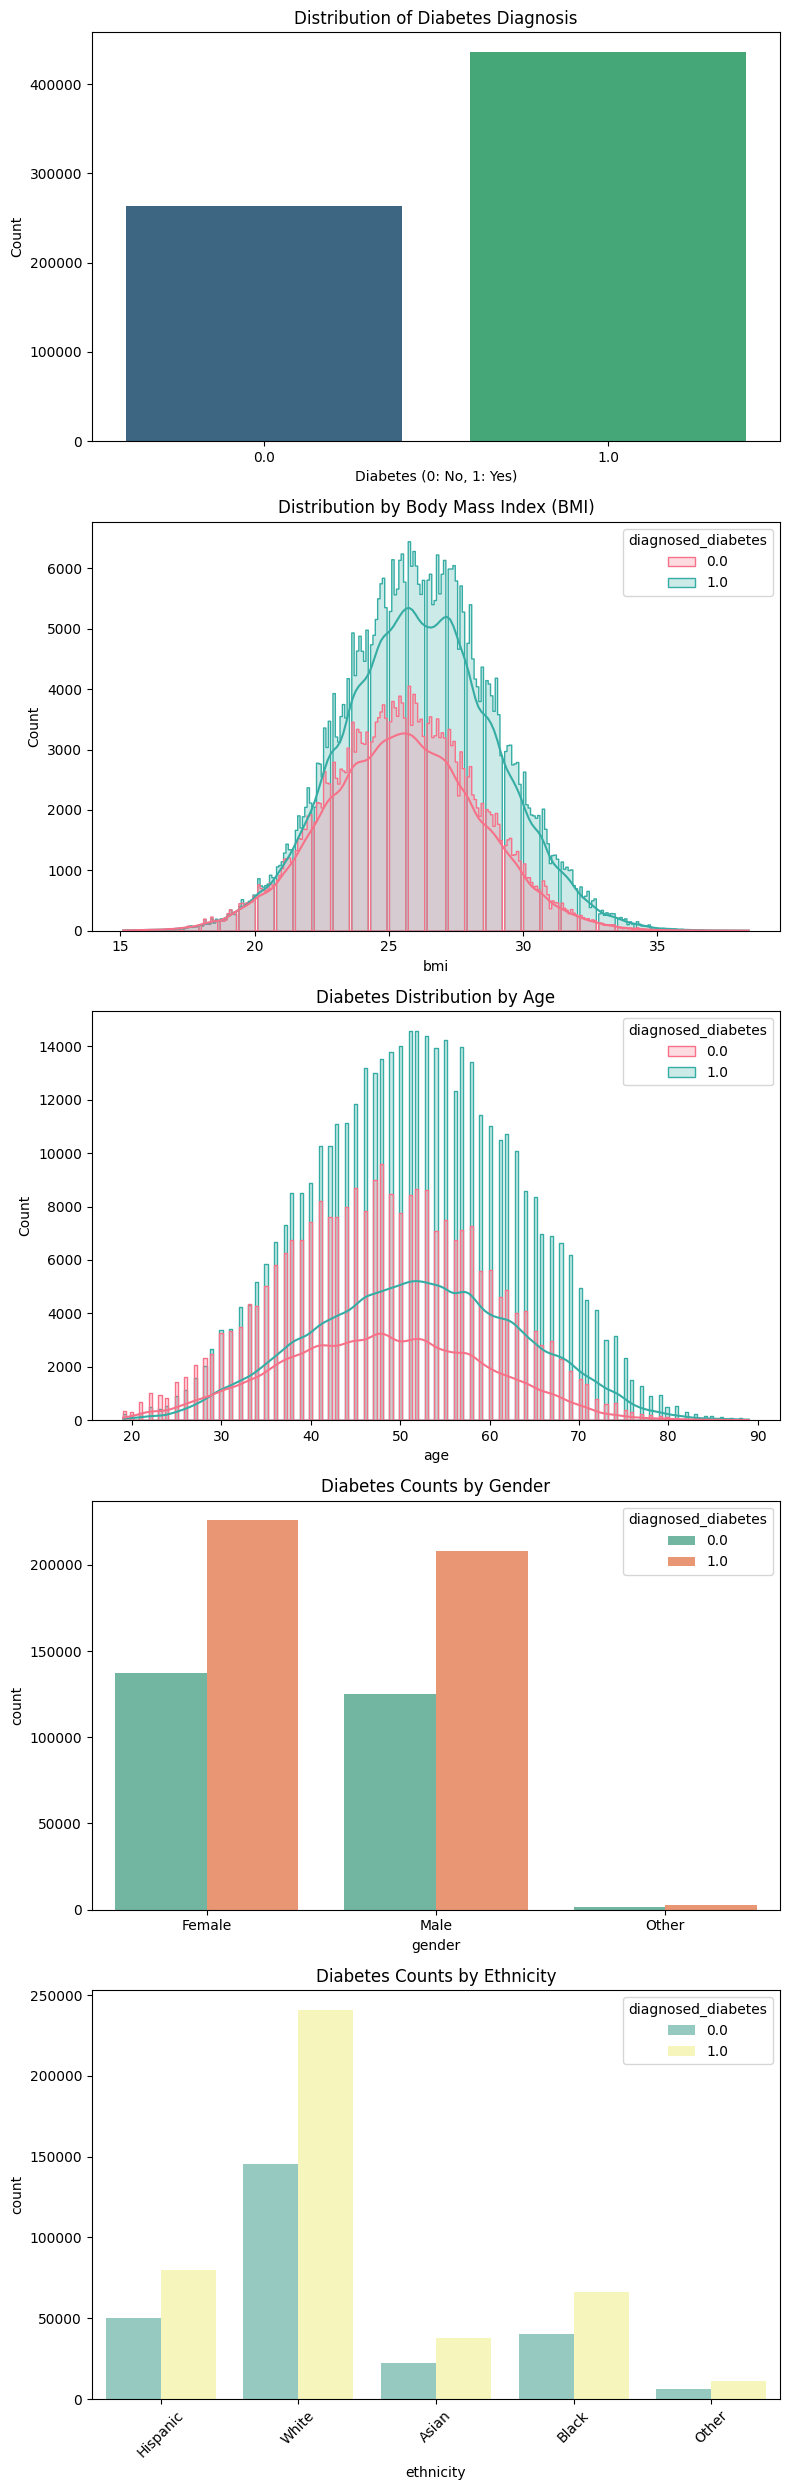

In [7]:
fig, axes = plt.subplots(5, 1, figsize=(8, 25))

sns.countplot(x='diagnosed_diabetes', data=train_df, ax=axes[0], palette='viridis')
axes[0].set_title('Distribution of Diabetes Diagnosis')
axes[0].set_xlabel('Diabetes (0: No, 1: Yes)')
axes[0].set_ylabel('Count')

sns.histplot(data=train_df, x='bmi', hue='diagnosed_diabetes', kde=True, element="step", ax=axes[1], palette='husl')
axes[1].set_title('Distribution by Body Mass Index (BMI)')

sns.histplot(data=train_df, x='age', hue='diagnosed_diabetes', kde=True, element="step", ax=axes[2], palette='husl')
axes[2].set_title('Diabetes Distribution by Age')

sns.countplot(x='gender', hue='diagnosed_diabetes', data=train_df, ax=axes[3], palette='Set2')
axes[3].set_title('Diabetes Counts by Gender')

sns.countplot(x='ethnicity', hue='diagnosed_diabetes', data=train_df, ax=axes[4], palette='Set3')
axes[4].set_title('Diabetes Counts by Ethnicity')
axes[4].tick_params(axis='x', rotation=45) # Rotate labels to prevent overlap

plt.tight_layout()
plt.show()

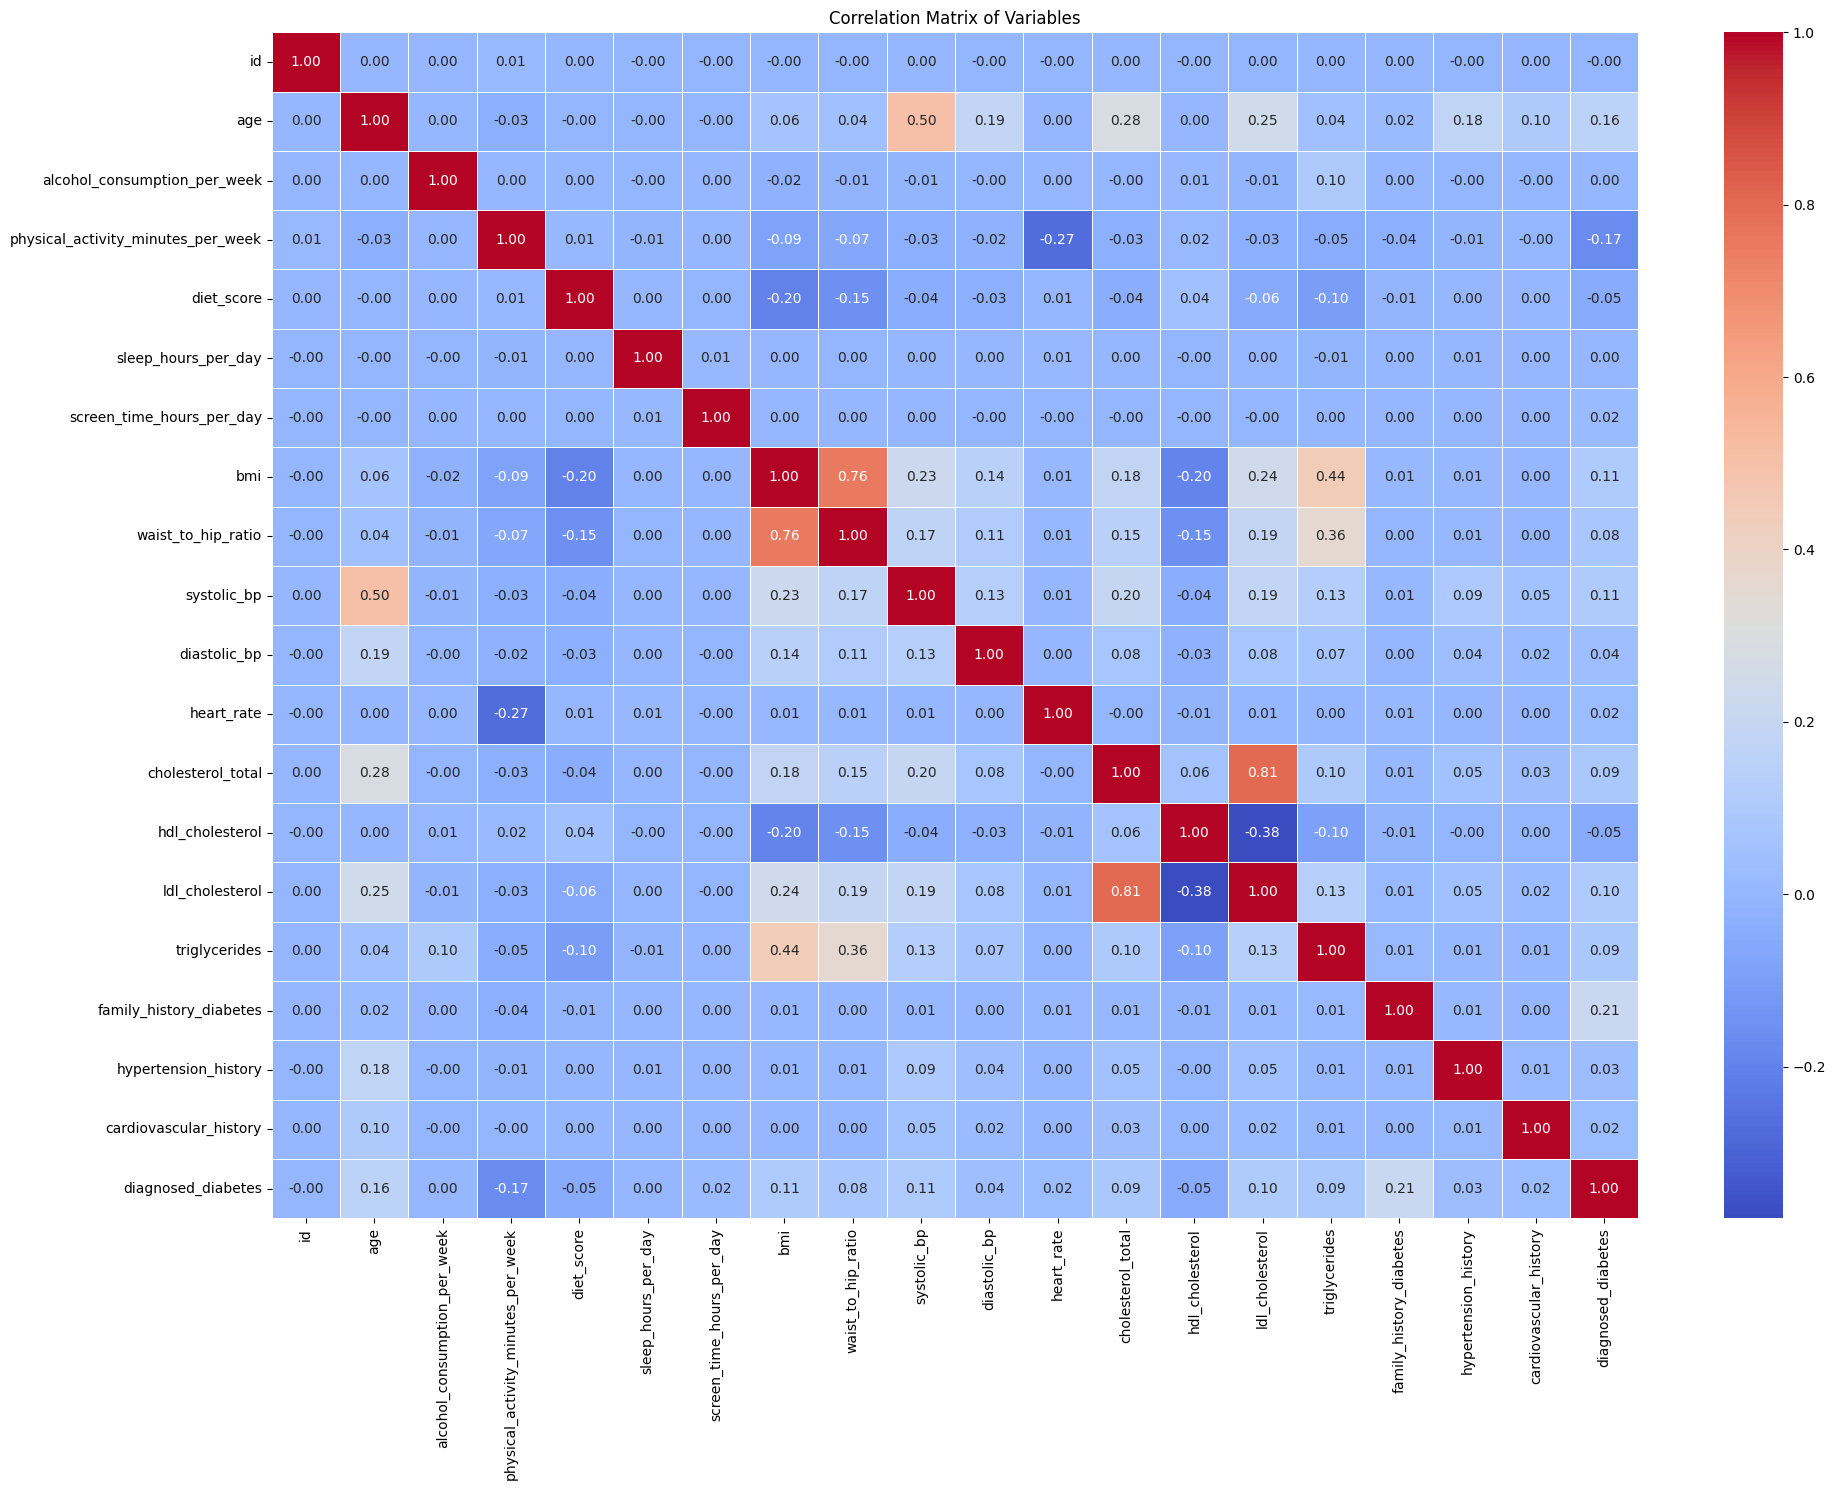

In [8]:
numeric_df = train_df.select_dtypes(include=['float64', 'int64'])
corr_matrix = numeric_df.corr()
plt.figure(figsize=(20, 15))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap='coolwarm', linewidths=0.5)
plt.title('Correlation Matrix of Variables')
plt.tight_layout()
plt.show()

## Analyzing Categorical Feature Impact
In this section, we analyze how different categories within each feature affect the probability of having diabetes compared to the global average.

- The **bars** represent the diabetes probability for that specific category.
- The **red dashed line** represents the global average diabetes rate across the entire dataset.
- The annotations on top of the bars show the absolute probability and the difference (lift) from the global average.

Global Diabetes Rate: 62.33%


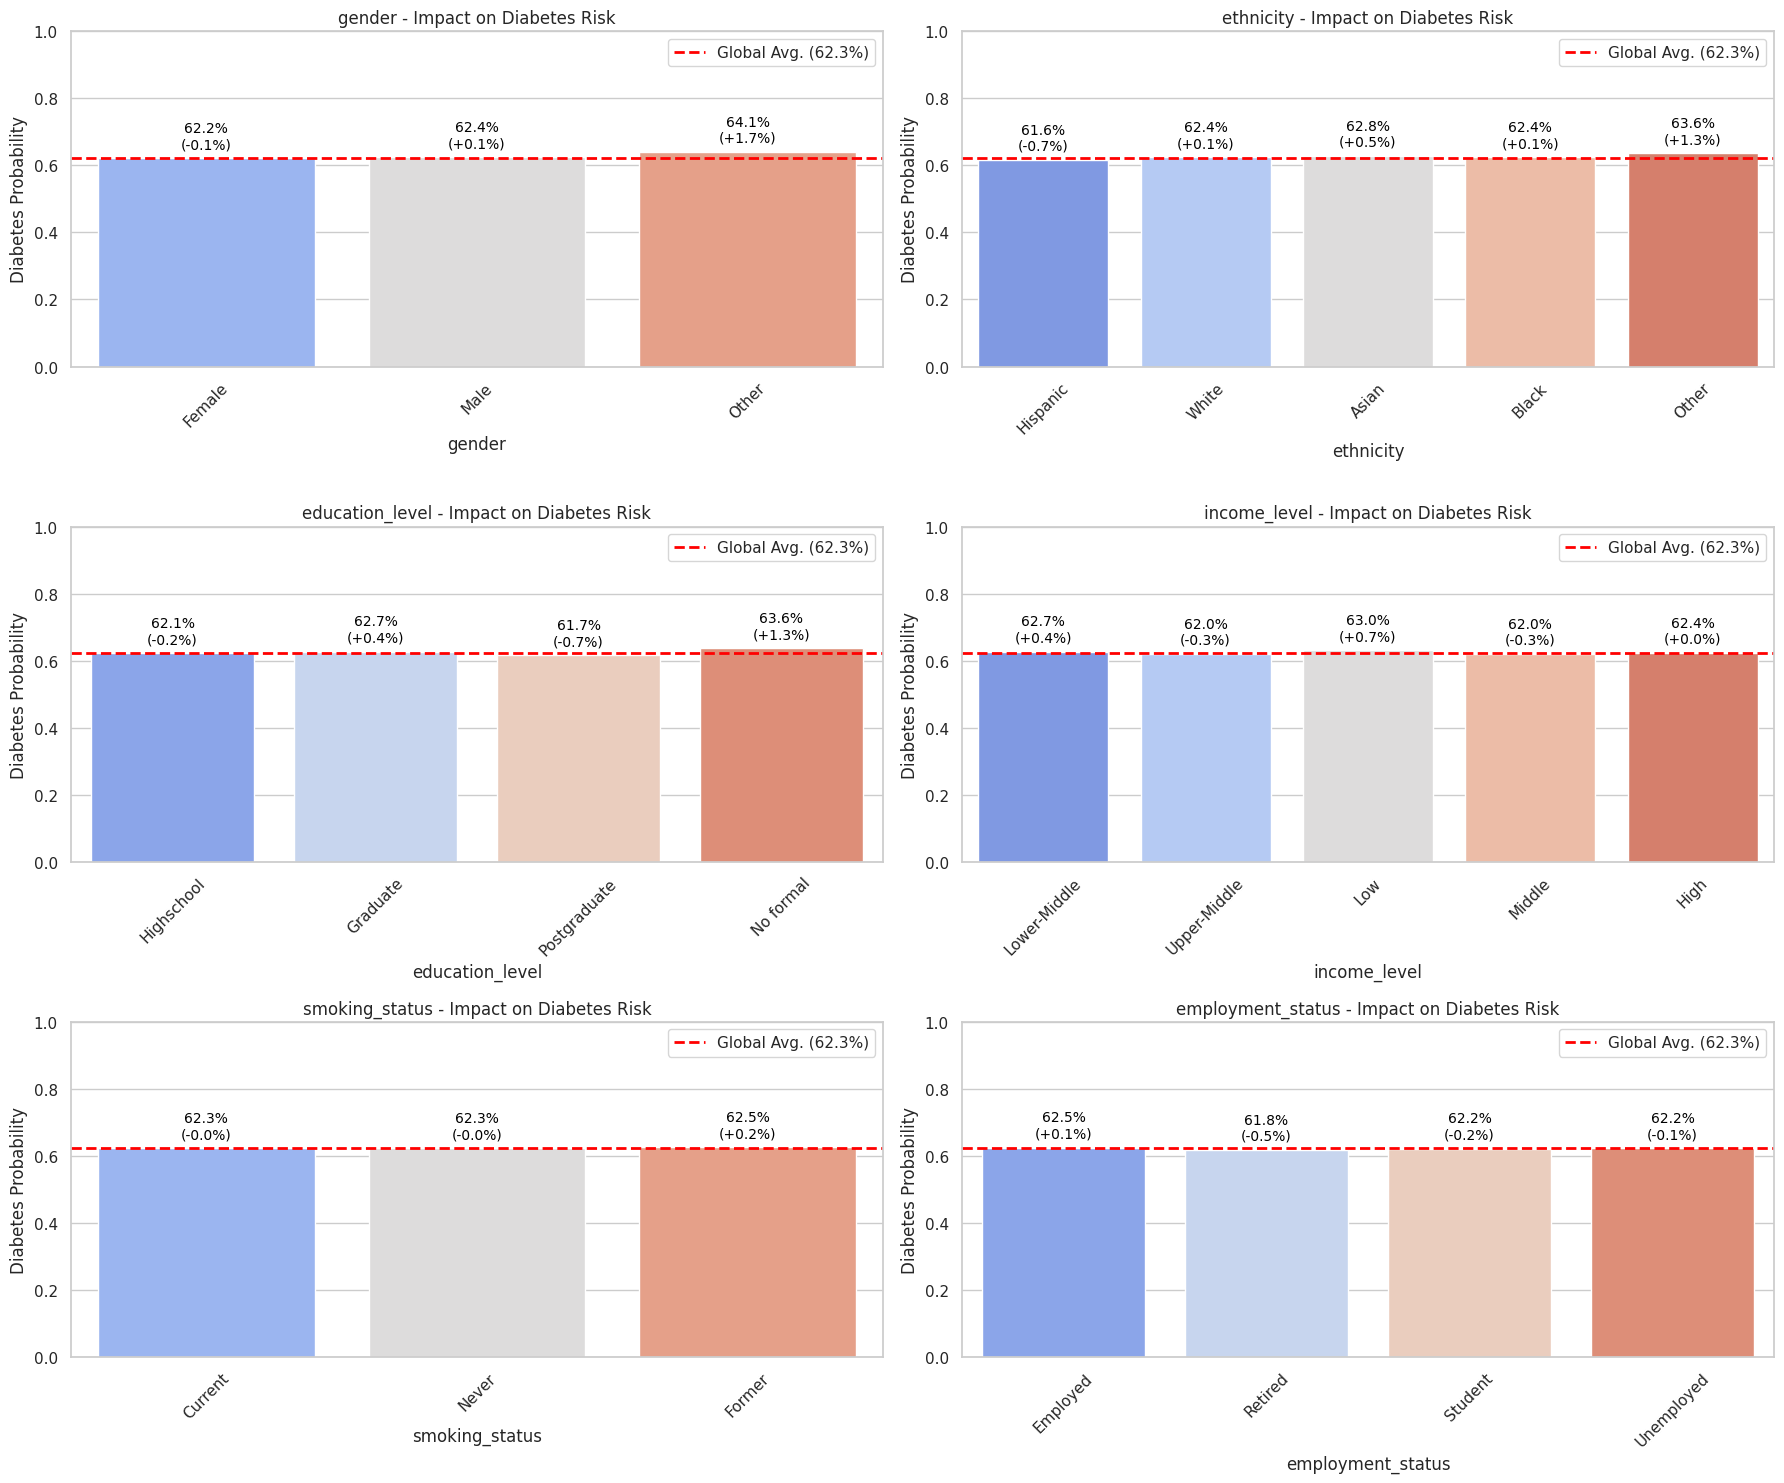

In [9]:
categorical_cols = train_df.select_dtypes(include=['object']).columns

global_rate = train_df['diagnosed_diabetes'].mean()
print(f"Global Diabetes Rate: {global_rate:.2%}")

sns.set(style="whitegrid")
n_cols = 2
n_rows = (len(categorical_cols) + 1) // n_cols

fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, 5 * n_rows))
axes = axes.flatten()

for i, col in enumerate(categorical_cols):
    
    sns.barplot(x=col, y='diagnosed_diabetes', data=train_df, ax=axes[i], palette='coolwarm', errorbar=None)

    axes[i].axhline(global_rate, color='red', linestyle='--', linewidth=2, label=f'Global Avg. ({global_rate:.1%})')

    axes[i].set_title(f'{col} - Impact on Diabetes Risk')
    axes[i].set_xlabel(col)
    axes[i].set_ylabel('Diabetes Probability')
    axes[i].tick_params(axis='x', rotation=45)
    axes[i].legend()
    axes[i].set_ylim(0, 1.0) 

    for p in axes[i].patches:
        height = p.get_height()
        if height > 0:
            diff = height - global_rate 
            diff_text = f"{height:.1%}\n({diff:+.1%})" 

            axes[i].annotate(diff_text, (p.get_x() + p.get_width() / 2., height),
                             ha='center', va='bottom', fontsize=10, color='black', xytext=(0, 5),
                             textcoords='offset points')

for i in range(len(categorical_cols), len(axes)):
    fig.delaxes(axes[i])

plt.tight_layout()
plt.show()

## Feature Selection: Dropping Columns
In this step, we remove specific columns from the dataset. This includes the `id` identifier and several demographic or lifestyle features (such as gender, ethnicity, and sleep hours) that we have decided to exclude from this specific model iteration to simplify the feature set.

In [10]:
cols_to_drop = [
    "id",
    "alcohol_consumption_per_week",
    "sleep_hours_per_day",
    "gender",
    "ethnicity",
    "education_level",
    "income_level",
    "smoking_status",
    "employment_status"
]

train_df = train_df.drop(cols_to_drop, axis=1, errors='ignore')
test_df = test_df.drop(cols_to_drop, axis=1, errors='ignore')

print(f"Dropped columns: {cols_to_drop}")
print(f"New Train shape: {train_df.shape}")

Dropped columns: ['id', 'alcohol_consumption_per_week', 'sleep_hours_per_day', 'gender', 'ethnicity', 'education_level', 'income_level', 'smoking_status', 'employment_status']
New Train shape: (700000, 17)


## Model Training & Evaluation (Hold-out Validation)
In this section, we split the training data into a **training set (80%)** and a **validation set (20%)** to evaluate our model's performance before submitting.

We use the **CatBoostClassifier** with the following configuration:
- **Metric**: AUC (Area Under Curve)
- **Early Stopping**: Stops training if the validation score doesn't improve for 100 rounds.
- **Depth & Learning Rate**: Tuned for a balance between speed and accuracy.

Finally, we visualize the **ROC Curve** and export the feature importance list to see which factors contributed most to the diagnosis.

# | CatBoost | 0.7254 

Train Set Size: (560000, 16)
Validation Set Size: (140000, 16)

Training model...
0:	test: 0.6776194	best: 0.6776194 (0)	total: 144ms	remaining: 4m 47s
100:	test: 0.7006194	best: 0.7006194 (100)	total: 8.08s	remaining: 2m 31s
200:	test: 0.7058331	best: 0.7058331 (200)	total: 16.1s	remaining: 2m 24s
300:	test: 0.7094951	best: 0.7094951 (300)	total: 24.1s	remaining: 2m 16s
400:	test: 0.7122112	best: 0.7122112 (400)	total: 32s	remaining: 2m 7s
500:	test: 0.7157467	best: 0.7157467 (500)	total: 40.2s	remaining: 2m
600:	test: 0.7182670	best: 0.7182670 (600)	total: 48.3s	remaining: 1m 52s
700:	test: 0.7197434	best: 0.7197434 (700)	total: 56.5s	remaining: 1m 44s
800:	test: 0.7207788	best: 0.7207788 (800)	total: 1m 4s	remaining: 1m 36s
900:	test: 0.7216110	best: 0.7216110 (900)	total: 1m 12s	remaining: 1m 28s
1000:	test: 0.7222848	best: 0.7222848 (1000)	total: 1m 20s	remaining: 1m 20s
1100:	test: 0.7229247	best: 0.7229247 (1100)	total: 1m 28s	remaining: 1m 12s
1200:	test: 0.7234427	best: 0.7234

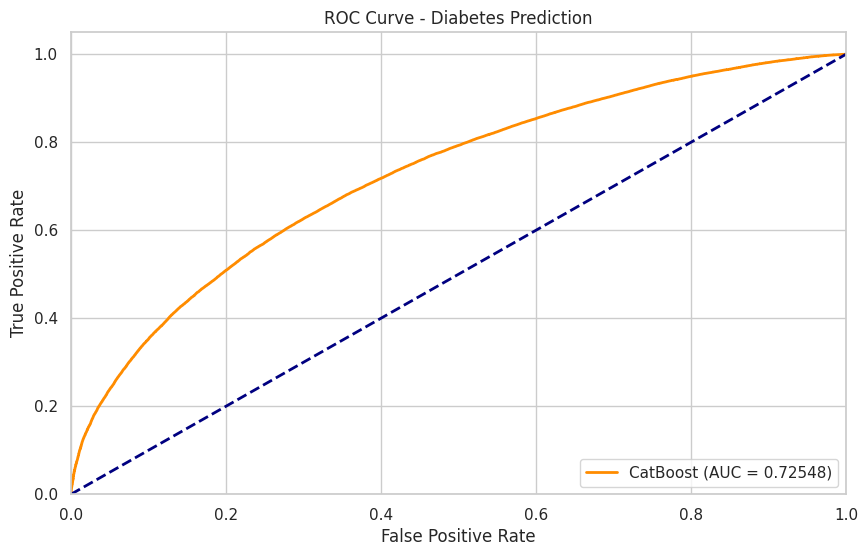

Validation Set AUC Score: 0.72548

Predicting on Test set...

Feature Importance Ranking:
                            Feature Id  Importances
0   physical_activity_minutes_per_week    34.336602
1              family_history_diabetes    30.662534
2                                  age    11.715781
3                        triglycerides     6.987890
4                                  bmi     3.154950
5                      ldl_cholesterol     2.212694
6                    cholesterol_total     1.876979
7                           heart_rate     1.634805
8                          systolic_bp     1.449191
9                           diet_score     1.435047
10                     hdl_cholesterol     1.365181
11                  waist_to_hip_ratio     1.183162
12           screen_time_hours_per_day     0.989664
13                        diastolic_bp     0.766541
14              cardiovascular_history     0.138527
15                hypertension_history     0.090452


In [11]:
from catboost import CatBoostClassifier, Pool
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_curve, auc

X = train_df.drop(columns=['diagnosed_diabetes'])
y = train_df['diagnosed_diabetes']
X_test = test_df 

X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print(f"Train Set Size: {X_train.shape}")
print(f"Validation Set Size: {X_val.shape}")

# CATBOOST MODEL TRAINING
print("\nTraining model...")

model = CatBoostClassifier(
    iterations=2000,            
    learning_rate=0.03,         
    depth=6,                    
    eval_metric='AUC',          
    random_seed=42,
    verbose=100,                
    early_stopping_rounds=100   
)

model.fit(
    X_train, y_train,
    eval_set=(X_val, y_val),
    use_best_model=True,
    plot=False
)

# PERFORMANCE EVALUATION (ROC CURVE)

y_val_probs = model.predict_proba(X_val)[:, 1]

fpr, tpr, thresholds = roc_curve(y_val, y_val_probs)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(10, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'CatBoost (AUC = {roc_auc:.5f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--') # Random guess line
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Diabetes Prediction')
plt.legend(loc="lower right")
plt.grid(True)
plt.show()

print(f"Validation Set AUC Score: {roc_auc:.5f}")


# PREDICTION

print("\nPredicting on Test set...")

test_preds = model.predict(X_test)

print("\nFeature Importance Ranking:")
feature_importance = model.get_feature_importance(prettified=True)
print(feature_importance)

# | LightGBM | 0.7265  
In addition to CatBoost, we train a **LightGBM (Light Gradient Boosting Machine)** model to compare performance. LightGBM is often faster and can provide excellent results on large datasets.

### Configuration:
- **LGBMClassifier**: We set `n_estimators=2000` and `learning_rate=0.03`, similar to our CatBoost setup.
- **Early Stopping**: We use a callback to stop training if the validation AUC doesn't improve for 100 rounds.
- **Evaluation**: The model performance is visualized using the ROC Curve on the validation set.

Train Set Size: (560000, 16)
Validation Set Size: (140000, 16)

Training model...

Drawing ROC Curve...


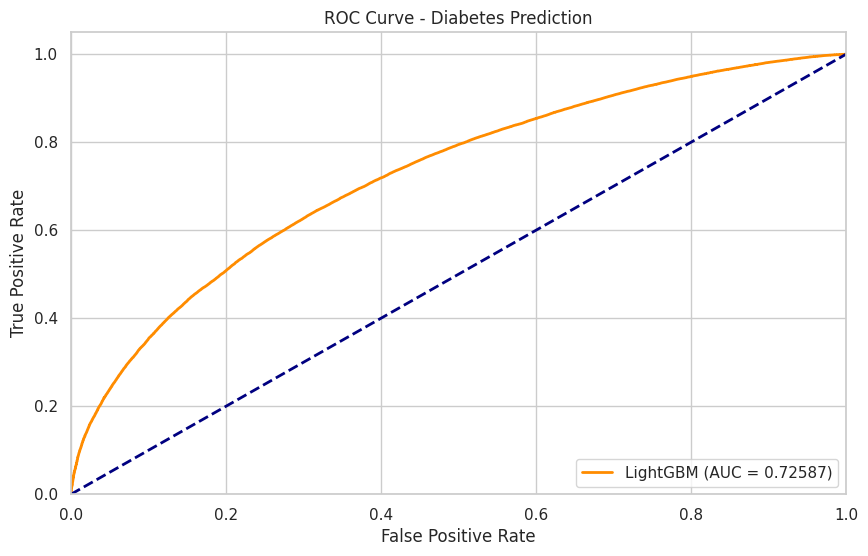

Validation Set AUC Score: 0.72587

Predicting on Test set...

Feature Importance Ranking:
                            Feature Id  Importances
1   physical_activity_minutes_per_week         7993
12                       triglycerides         3666
0                                  age         2764
4                                  bmi         2732
9                    cholesterol_total         2334
11                     ldl_cholesterol         2128
3            screen_time_hours_per_day         2013
6                          systolic_bp         1978
8                           heart_rate         1944
2                           diet_score         1854
10                     hdl_cholesterol         1710
7                         diastolic_bp         1478
5                   waist_to_hip_ratio         1302
13             family_history_diabetes          342
14                hypertension_history          134
15              cardiovascular_history           98


In [12]:
from lightgbm import LGBMClassifier
from lightgbm.callback import early_stopping

X = train_df.drop(columns=['diagnosed_diabetes'])
y = train_df['diagnosed_diabetes']
X_test = test_df 

X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print(f"Train Set Size: {X_train.shape}")
print(f"Validation Set Size: {X_val.shape}")

# LIGHTGBM MODEL TRAINING
print("\nTraining model...")

model = LGBMClassifier(
    n_estimators=2000,          
    learning_rate=0.03,        
    num_leaves=31,              
    n_jobs=-1,
    verbose=-1                  
)

model.fit(
    X_train, y_train,
    eval_set=[(X_val, y_val)],
    eval_metric='auc',          # Use ROC AUC metric
    callbacks=[early_stopping(stopping_rounds=100, verbose=False)] # Correct usage for early stopping
)

# PERFORMANCE EVALUATION (ROC CURVE)
print("\nDrawing ROC Curve...")

y_val_probs = model.predict_proba(X_val)[:, 1]

fpr, tpr, thresholds = roc_curve(y_val, y_val_probs)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(10, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'LightGBM (AUC = {roc_auc:.5f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--') 
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Diabetes Prediction')
plt.legend(loc="lower right")
plt.grid(True)
plt.show()

print(f"Validation Set AUC Score: {roc_auc:.5f}")

# PREDICTION
print("\nPredicting on Test set...")

test_preds = model.predict(X_test)

print("\nFeature Importance Ranking:")
feature_importance = pd.DataFrame({
    'Feature Id': X_train.columns,
    'Importances': model.feature_importances_
}).sort_values(by='Importances', ascending=False)
print(feature_importance)